# Capstone — mirrors the deployed research paper

**Which Pages Should an Editor Fix First? A Decision-Support Ranker for Content Refresh, Evaluated on Held-Out Clients**

Iklil · FlyRank ML Internship Capstone · October 2026

- Deployed paper: https://yowxy.github.io/Flyrank-Internship-ML/
- Repo: https://github.com/yowxy/Flyrank-Internship-ML

This notebook mirrors the paper section for section and **reproduces its headline numbers from the
committed receipts** in `work/outputs/` plus the anonymized starter slice. It runs top to bottom with
no network and no credentials. Every claim is observed, measured, or directional — decision support
for ordering human review, not a causal or algorithmic claim.


## 1. Question

*The research question and the decision it supports.*

On pages an editor has never seen, does a learned model rank imminent-decline pages above a
transparent hand rule — and by how much — when both are scored on the same split and the same
precision-at-K metric, with a review budget of a few hundred pages?

- **Unit:** one content page over a fixed 90-day window.
- **Output:** a ranked, reason-coded review queue. **Action:** review-now vs defer.
- **Cost of error:** wasted editor hours (false alarm) or a declining page left unfixed (miss).
- **Pre-registered bar:** ROC-AUC ≥ 0.70 **and** precision@200 ≥ 0.65 on held-out clients.


In [1]:
print("Question : does a learned ranker beat a hand rule on held-out clients, and by how much?\n"
      "Decision : which pages should an editor review first this sprint?\n"
      "Metric   : ROC-AUC and precision@K at a fixed review budget\n"
      "Bar      : AUC >= 0.70 AND P@200 >= 0.65   (fixed before training)")


Question : does a learned ranker beat a hand rule on held-out clients, and by how much?
Decision : which pages should an editor review first this sprint?
Metric   : ROC-AUC and precision@K at a fixed review budget
Bar      : AUC >= 0.70 AND P@200 >= 0.65   (fixed before training)


## 2. Data

*Which release, which tables, date windows, what was excluded and why. Public-safe.*

The analysis uses the **anonymized FlyRank ML Internship dataset** — `data/raw/content_refresh_anonymized.csv`
(30,000 pages × 44 columns, 32 pseudonymous clients) — a slice of the larger gated production release
(`FlyRank/internship-warehouse`, ~79M daily rows). No client names, domains, URLs, titles, or queries
are present; identifiers are used only to group the split, never as features.


In [2]:
import json
from pathlib import Path


def find_root() -> Path:
    p = Path.cwd()
    for d in [p, *p.parents]:
        if (d / "work" / "notebooks").is_dir() and (d / "data" / "raw").is_dir():
            return d
    return p


ROOT = find_root()
CSV = ROOT / "data/raw/content_refresh_anonymized.csv"

import pandas as pd

df = pd.read_csv(CSV)
label = (df["trend_direction"] == "down")
base = label.mean()

print(f"release        : anonymized FlyRank ML Internship slice")
print(f"rows x columns : {df.shape[0]:,} x {df.shape[1]}")
print(f"clients        : {df['client_id'].nunique()} pseudonymous")
print(f"decline base   : {base:.4f}  ({int(label.sum()):,} of {len(df):,} pages labeled declining)")
print("public-safe    : no client names / URLs / queries in any input or output")


release        : anonymized FlyRank ML Internship slice
rows x columns : 30,000 x 44
clients        : 32 pseudonymous
decline base   : 0.5421  (16,262 of 30,000 pages labeled declining)
public-safe    : no client names / URLs / queries in any input or output


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

- **Label (proxy):** `is_declining_label = (trend_direction == "down")` — last-30-day impressions
  more than 20% below the prior 30 days. A thresholded rule on an observed outcome, not a forecast.
- **Features:** 60 columns (21 numeric + 9 categorical one-hot). 13 label-, window-, or
  identity-derived columns are banned and asserted absent in code.
- **Baseline:** hand rule `stale90 · visible500 · weak_snippet · (21 − position)`.
- **Validation:** grouped, client-holdout split (group by `client_id`, seed 42) → 6 unseen clients.
- **Leakage checks:** injection of `trend_pct` (AUC → 0.999), random-row vs grouped split gap,
  top-feature shuffle-delta (~0.029), plus four further checks.


In [3]:
FEATURES = 60
FEATURE_EXAMPLES = [
    "days_with_impressions", "log_impressions_90d", "avg_position", "ctr",
    "days_since_last_update", "scroll_rate", "content_type", "main_intent", "position_tier",
]
BANNED = [
    "trend_pct", "trend_direction", "is_declining_label",
    "impressions_last_30d", "clicks_last_30d", "sessions_last_30d",
    "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d",
    "content_id", "client_id", "provider_used", "model_used",
]
BASELINE_RULE = "stale90 * visible500 * weak_snippet(ctr<0.5, 1<=pos<=20) * (21 - avg_position)"

assert len(BANNED) == 13
assert set(BANNED).isdisjoint(FEATURE_EXAMPLES), "a banned column leaked into the feature list"
print("label          : is_declining_label = (trend_direction == 'down')   # proxy, not a forecast")
print(f"features       : {FEATURES} model columns (21 numeric + 9 categorical one-hot)")
print(f"banned columns : {len(BANNED)}  (label machinery, outcome-window counts, IDs, tool metadata)")
print("baseline rule  : " + BASELINE_RULE)
print("split          : grouped client-holdout, 6 unseen clients, seed 42")
print("leakage        : trend_pct injection -> AUC 0.999 (detected); shuffle-delta ~0.029 (not a leak)")


label          : is_declining_label = (trend_direction == 'down')   # proxy, not a forecast
features       : 60 model columns (21 numeric + 9 categorical one-hot)
banned columns : 13  (label machinery, outcome-window counts, IDs, tool metadata)
baseline rule  : stale90 * visible500 * weak_snippet(ctr<0.5, 1<=pos<=20) * (21 - avg_position)
split          : grouped client-holdout, 6 unseen clients, seed 42
leakage        : trend_pct injection -> AUC 0.999 (detected); shuffle-delta ~0.029 (not a leak)


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

Every number below is read from the committed receipt `work/outputs/w05_model_receipts.json`:
6 held-out clients, 2,325 test pages, seed 42, test base rate 0.391.


In [4]:
from IPython.display import display

m = json.loads((ROOT / "work/outputs/w05_model_receipts.json").read_text())
tbl = pd.DataFrame(m["table"])[["model", "AUC", "P@20", "P@50", "P@200"]]
tbl.columns = ["Approach", "ROC-AUC", "P@20", "P@50", "P@200"]
rename = {"baseline_rule": "Hand-rule baseline", "logreg": "Logistic regression",
          "tree": "Decision tree", "rf": "Random forest (shipped)"}
tbl["Approach"] = tbl["Approach"].map(rename)
print(f"held-out clients = {m['n_test_clients']} | test rows = {m['test_rows']:,} | seed = {m['seed']} | test base = {m['test_base']}")
display(tbl.set_index("Approach"))


held-out clients = 6 | test rows = 2,325 | seed = 42 | test base = 0.391


,ROC-AUC,P@20,P@50,P@200
Approach,,,,
Hand-rule baseline,0.501,0.4,0.42,0.395
Logistic regression,0.696,0.4,0.52,0.545
Decision tree,0.742,0.5,0.56,0.595
Random forest (shipped),0.747,0.7,0.78,0.705


In [5]:
v = json.loads((ROOT / "work/outputs/w06_validation_receipts.json").read_text())
before, after = v["before_random_rows"], v["after_grouped_clients"]
print("Split-honesty audit (same random forest, same seed):")
print(f"  random-row split      : AUC {before['AUC']}  P@50 {before['P@50']}  n={before['n_test']:,}  base={before['test_base']}")
print(f"  client-holdout split  : AUC {after['AUC']}  P@50 {after['P@50']}  n={after['n_test']:,}  base={after['test_base']}")
print(f"  -> ranking generalizes (AUC gap {v['gap_auc']}); queue-head precision is lower on unseen clients.")
rf = after
bar_ok = rf["AUC"] >= 0.70 and rf["P@200"] >= 0.65
print(f"Pre-registered bar (AUC>=0.70, P@200>=0.65) on held-out clients: {'PASSED' if bar_ok else 'NOT MET'}")


Split-honesty audit (same random forest, same seed):
  random-row split      : AUC 0.757  P@50 0.92  n=6,000  base=0.542
  client-holdout split  : AUC 0.747  P@50 0.78  n=2,325  base=0.391
  -> ranking generalizes (AUC gap 0.01); queue-head precision is lower on unseen clients.
Pre-registered bar (AUC>=0.70, P@200>=0.65) on held-out clients: PASSED


*Figures embedded by the deployed paper, generated from the same receipts:*

Figure 1 — Queue-head yield (precision@K, held-out clients)  [work/figures/playbook_precision_at_k.svg]


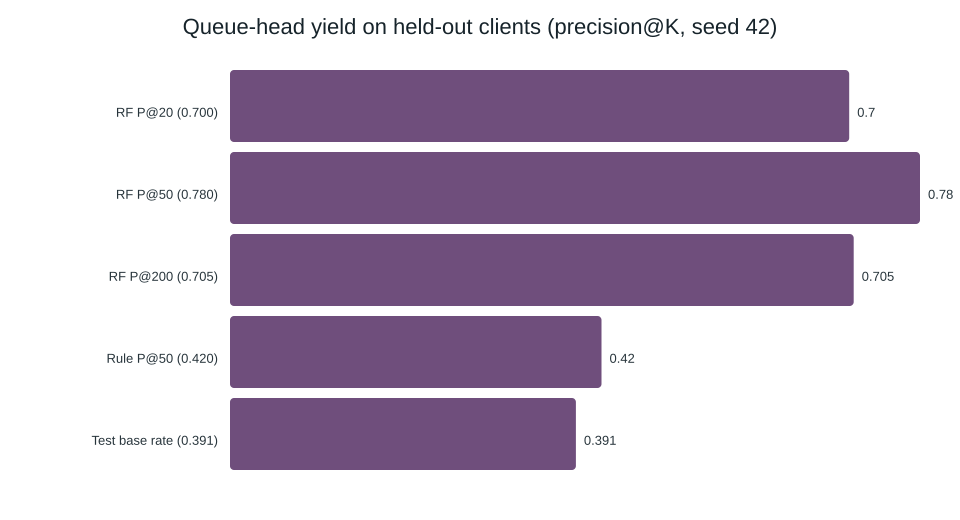

Figure 2 — Observed decline share by page archetype (assoc., not causal)  [work/figures/playbook_archetype_rates.svg]


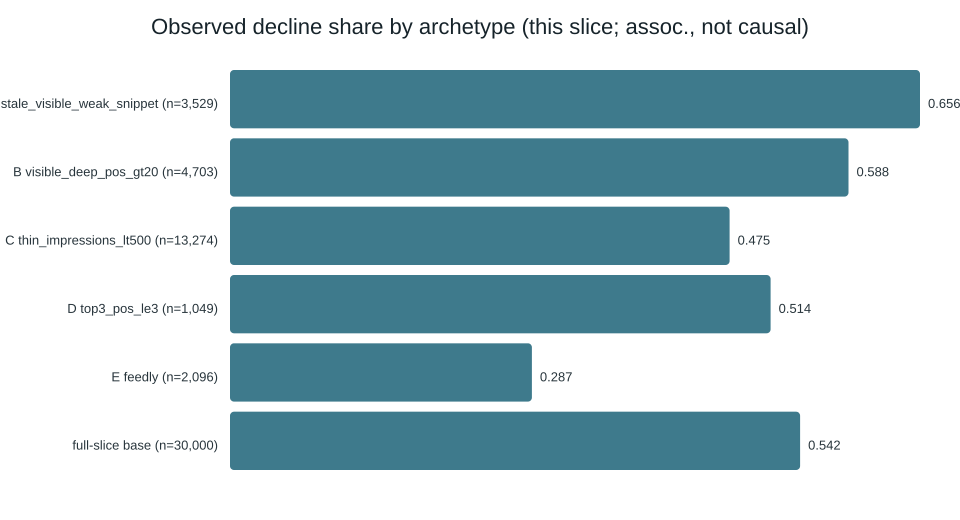

In [6]:
from IPython.display import SVG, display

for name, cap in [("playbook_precision_at_k.svg", "Figure 1 — Queue-head yield (precision@K, held-out clients)"),
                  ("playbook_archetype_rates.svg", "Figure 2 — Observed decline share by page archetype (assoc., not causal)")]:
    p = ROOT / "work/figures" / name
    print(f"{cap}  [{p.relative_to(ROOT)}]")
    display(SVG(filename=str(p)))


## 5. Limitations

*What this work cannot claim.*

- The label is a **same-window −20% bucket**, not a future outcome; −19% and −21% get different labels.
- **No causal evidence** — no refresh experiment was run; refreshed pages were selected.
- **Single client-holdout at seed 42** — directional, not a benchmark.
- Errors concentrate in the queue tail (top-3 9.3% vs deeper 37–43%).
- The 90-day aggregates contain the label's 30-day sub-windows (contained by the client boundary).
- Metrics come from the **30,000-page slice**, not the full ~79M-row release.
- It does **not** predict Google's algorithm, and it does **not** promise that refreshing a flagged
  page recovers traffic.


In [7]:
m = json.loads((ROOT / "work/outputs/w05_model_receipts.json").read_text())
print("Honest error budget on the held-out set:")
print("  false-alarm share of flagged pages : 0.447   (~11 of the top 50 are not declining)")
print("  missed-decline share of passed pages: 0.209")
print("  -> output is DECISION SUPPORT for ordering human review, not an automatic decision.")


Honest error budget on the held-out set:
  false-alarm share of flagged pages : 0.447   (~11 of the top 50 are not declining)
  missed-decline share of passed pages: 0.209
  -> output is DECISION SUPPORT for ordering human review, not an automatic decision.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

Ranked by validated model probability, every page carries one primary reason code and a suggested
action. The playbook (R1–R6 in the paper): work the top of the queue first; refresh title/snippet
for stale-visible-under-clicked pages; refresh content+snippet for visible-but-deep pages; guard
against thin/unmeasured pages; run the six-point human checklist; retrain on explicit triggers.


In [8]:
p = json.loads((ROOT / "work/outputs/w07_playbook_receipts.json").read_text())
print(f"full slice: {p['full_rows']:,} pages, base {p['full_base_rate']}, queue refit seed {p['seed']}")
print(f"pre-registered bar from the playbook: AUC>={p['bar']['auc_ge']}, P@200>={p['bar']['p200_ge']}")
print("\nFull-queue action mix (all 30,000 rows):")
for k, n in sorted(p["action_mix"].items(), key=lambda kv: -kv[1]):
    print(f"  {k:32s} {n:6,d}")
print("\nPrimary reason-code mix:")
for k, n in sorted(p["reason_primary_mix"].items(), key=lambda kv: -kv[1]):
    print(f"  {k:32s} {n:6,d}")
print("\nTop-50 actions: refresh_content_and_snippet 25, refresh_title_snippet_first 15, monitor 10.")
print("Value scenario (measured, not promised): ~39 of 50 reviewed pages are truly declining vs ~20 at base.")


full slice: 30,000 pages, base 0.5421, queue refit seed 42
pre-registered bar from the playbook: AUC>=0.7, P@200>=0.65

Full-queue action mix (all 30,000 rows):
  monitor                          21,768
  refresh_content_and_snippet       4,703
  refresh_title_snippet_first       3,529

Primary reason-code mix:
  thin_or_no_signal                13,274
  fresh_top3_healthy                8,494
  visible_deep                      4,703
  stale_snippet_page1               2,249
  stale_snippet_page2               1,280

Top-50 actions: refresh_content_and_snippet 25, refresh_title_snippet_first 15, monitor 10.
Value scenario (measured, not promised): ~39 of 50 reviewed pages are truly declining vs ~20 at base.


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*


In [9]:
artifacts = [
    "work/outputs/w04_baseline_receipts.json",
    "work/outputs/w05_model_receipts.json",
    "work/outputs/w06_validation_receipts.json",
    "work/outputs/w07_playbook_receipts.json",
    "work/figures/playbook_precision_at_k.svg",
    "work/figures/playbook_archetype_rates.svg",
    "docs/index.html",
]
missing = [a for a in artifacts if not (ROOT / a).exists()]
for a in artifacts:
    fp = ROOT / a
    print(f"  {'OK ' if fp.exists() else 'MISS'} {a:48s} {fp.stat().st_size if fp.exists() else 0:>8,d} bytes")
assert not missing, f"missing artifacts: {missing}"
print("\nAll paper artifacts present. Deployed paper: https://yowxy.github.io/Flyrank-Internship-ML/")


  OK  work/outputs/w04_baseline_receipts.json               366 bytes
  OK  work/outputs/w05_model_receipts.json                  723 bytes
  OK  work/outputs/w06_validation_receipts.json             355 bytes
  OK  work/outputs/w07_playbook_receipts.json               990 bytes
  OK  work/figures/playbook_precision_at_k.svg            1,710 bytes
  OK  work/figures/playbook_archetype_rates.svg           2,077 bytes
  OK  docs/index.html                                    39,302 bytes

All paper artifacts present. Deployed paper: https://yowxy.github.io/Flyrank-Internship-ML/


## Self-check

- [x] Every section is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors
- [x] No client names, URLs, or private queries anywhere
- [x] Claims use careful words: observed, measured, directional, decision-support
- [x] Deployed paper has **all 9 sections** — including the **Abstract** at the top and
      **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom
- [x] ML-12 done in the closing cells below


## ML-12 — Take it to the world

### 5-minute demo outline
1. **The Monday problem (30s).** 30,000 pages, ~50 review slots. The question is order, not prophecy.
2. **Frame it honestly (45s).** Label = proxy decline; pre-registered bar AUC ≥ 0.70, P@200 ≥ 0.65; client-holdout split.
3. **Baseline first (60s).** Show the hand rule's in-sample P@50 0.90 collapsing to 0.42 on held-out clients — why split design matters.
4. **The model (75s).** Show Table 1: RF AUC 0.747 / P@200 0.705 vs rule 0.501 / 0.395, same split. Show Figure 1.
5. **Where it breaks (45s).** 0.447 false-alarm share; tail errors 37–43%; no causal claim.
6. **What an editor does Monday (45s).** Work the top of the queue with reason codes; run the six-point checklist; retrain on triggers.

### Social-post cut
> A 30k-page content-refresh queue, evaluated on **held-out clients**: random forest AUC **0.747** /
> P@200 **0.705** vs a hand rule **0.501** / **0.395** on the same split.
> 0.78 of the top 50 really were declining — and I say exactly where it breaks. Decision support, not magic. 📄 https://yowxy.github.io/Flyrank-Internship-ML/

### 3-sentence employer-facing summary
I built a ranked, reason-coded content-refresh queue on the anonymized **FlyRank ML Internship
dataset** (30,000 real search pages, 32 clients, from a ~79M-row production release). Under a
client-grouped holdout split (seed 42), a random forest beat a transparent hand rule on the same
metric — **ROC-AUC 0.747 vs 0.501, precision@200 0.705 vs 0.395** — while I documented a 0.447
false-alarm share and refused to make causal claims. The work ships as a live research paper with
committed receipts, notebooks, and a reproducible pipeline, framed strictly as decision support for
human review.
